# 07 · Threshold Tuning & Business Value

The final model is **Gradient Boosting** (best ROC-AUC, notebooks 05–06). Two questions remain:

1. **Which probability threshold** should count as "call this client"? The default 0.5 finds only a quarter of subscribers.
2. **What is the model worth to the bank?** If the team calls only the top-scored clients, what share of all subscribers do they reach?

The threshold is chosen on **training data only** (out-of-fold predictions), then applied once to the test set.

In [1]:
import sys, json
sys.path.append('../src')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from prep import load_data, split, tree_preprocessor, evaluate, save_result, RANDOM_STATE

from sklearn.pipeline import make_pipeline
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import precision_recall_curve, ConfusionMatrixDisplay

sns.set_theme(style='whitegrid')
df = load_data()
X_train, X_test, y_train, y_test = split(df)
best = json.load(open('../results/best_params.json'))
gb_params = {k.replace('model__', ''): v for k, v in best['gradient_boosting'].items()}
gb_pipe = make_pipeline(tree_preprocessor(), GradientBoostingClassifier(random_state=RANDOM_STATE, **gb_params))

## 1. Out-of-fold probabilities on the training set

In [2]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
oof = cross_val_predict(gb_pipe, X_train, y_train, cv=cv, method='predict_proba', n_jobs=-1)[:, 1]

precision, recall, thresholds = precision_recall_curve(y_train, oof)
precision, recall = precision[:-1], recall[:-1]          # thresholds has one fewer value
f1 = 2 * precision * recall / (precision + recall + 1e-12)
best_i = np.argmax(f1)
threshold = float(thresholds[best_i])
print(f'F1-optimal threshold: {threshold:.3f}  (train OOF precision {precision[best_i]:.3f}, recall {recall[best_i]:.3f}, F1 {f1[best_i]:.3f})')

F1-optimal threshold: 0.161  (train OOF precision 0.438, recall 0.556, F1 0.490)


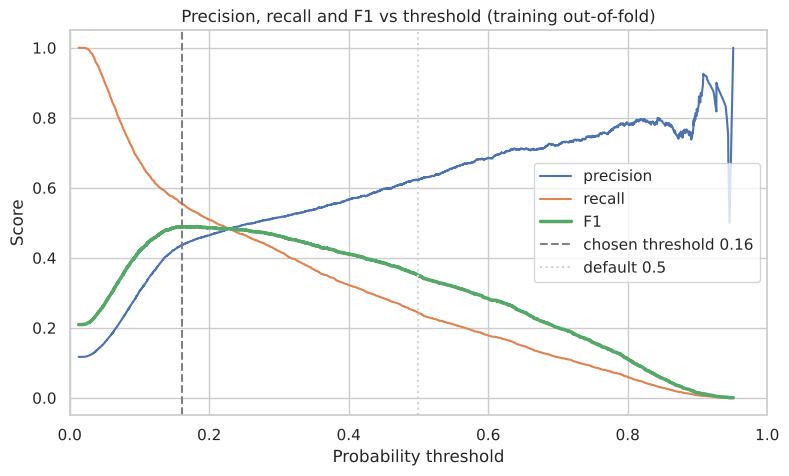

In [3]:
plt.figure(figsize=(9, 5))
plt.plot(thresholds, precision, label='precision')
plt.plot(thresholds, recall, label='recall')
plt.plot(thresholds, f1, label='F1', lw=2.5)
plt.axvline(threshold, color='grey', ls='--', label=f'chosen threshold {threshold:.2f}')
plt.axvline(0.5, color='lightgrey', ls=':', label='default 0.5')
plt.xlabel('Probability threshold'); plt.ylabel('Score')
plt.title('Precision, recall and F1 vs threshold (training out-of-fold)')
plt.legend(); plt.xlim(0, 1); plt.show()

## 2. Apply the threshold to the test set

In [4]:
proba_test = pd.read_csv('../results/test_probas.csv')['gradient_boosting'].values   # model fit on the full training set in notebook 05
default = evaluate('Gradient Boosting', y_test, proba_test, threshold=0.5)
tuned = evaluate('Gradient Boosting (tuned threshold)', y_test, proba_test, threshold=round(threshold, 3))
pd.DataFrame([default, tuned]).round(3)

,model,threshold,accuracy,balanced_accuracy,precision,recall,f1,roc_auc
0,Gradient Boosting,0.500,0.897,0.618,0.660,0.253,0.366,0.806
1,Gradient Boosting (tuned threshold),0.161,0.866,0.732,0.443,0.556,0.493,0.806


In [5]:
save_result(tuned)

,model,threshold,accuracy,balanced_accuracy,precision,recall,f1,roc_auc
0,Baseline (always no),0.500,0.8830,0.5000,0.0000,0.0000,0.0000,0.5000
1,Logistic Regression,0.500,0.7734,0.7130,0.2876,0.6342,0.3958,0.7789
2,Decision Tree,0.500,0.8143,0.7210,0.3356,0.5992,0.4303,0.7784
3,Random Forest,0.500,0.8254,0.7416,0.3599,0.6323,0.4587,0.8039
4,Gradient Boosting,0.500,0.8974,0.6180,0.6601,0.2533,0.3661,0.8057
5,Gradient Boosting (tuned threshold),0.161,0.8664,0.7317,0.4434,0.5558,0.4933,0.8057


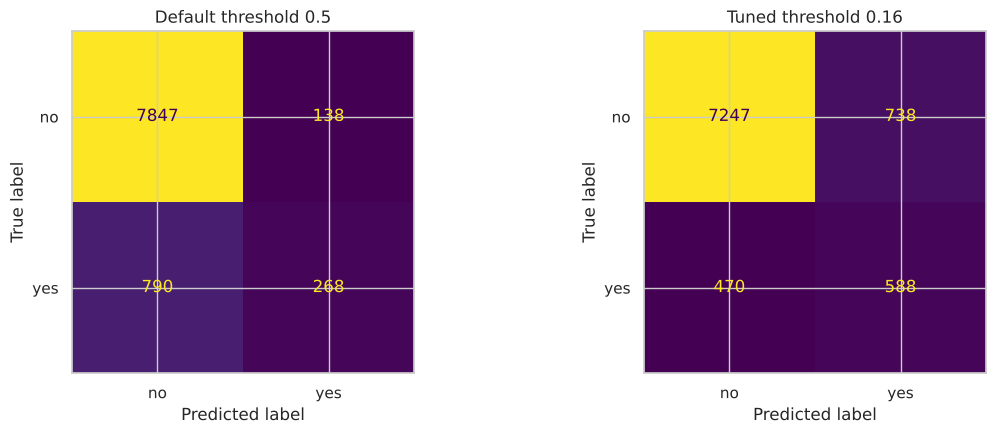

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, t, title in [(axes[0], 0.5, 'Default threshold 0.5'), (axes[1], threshold, f'Tuned threshold {threshold:.2f}')]:
    ConfusionMatrixDisplay.from_predictions(y_test, (proba_test >= t).astype(int), display_labels=['no', 'yes'],
                                            ax=ax, colorbar=False)
    ax.set_title(title)
plt.tight_layout(); plt.show()

## 3. Business value: calling only the top-scored clients

In [7]:
probas = pd.read_csv('../results/test_probas.csv')
total_yes = probas['y_true'].sum()
rows = []
for share in [0.10, 0.20, 0.30, 0.50]:
    n = int(round(share * len(probas)))
    row = {'call_top_%': int(share * 100), 'calls': n}
    for col, label in [('gradient_boosting', 'GB'), ('logistic_regression', 'LR')]:
        top = probas.sort_values(col, ascending=False).head(n)
        row[f'{label}_subscribers_reached_%'] = round(top['y_true'].sum() / total_yes * 100, 1)
        row[f'{label}_yes_rate_in_called_%'] = round(top['y_true'].mean() * 100, 1)
    row['random_calls_reach_%'] = int(share * 100)
    rows.append(row)
value = pd.DataFrame(rows)
print(f'Test set: {len(probas):,} clients, {total_yes:,} subscribers ({total_yes / len(probas):.1%})')
value

Test set: 9,043 clients, 1,058 subscribers (11.7%)


,call_top_%,calls,GB_subscribers_reached_%,GB_yes_rate_in_called_%,LR_subscribers_reached_%,LR_yes_rate_in_called_%,random_calls_reach_%
0,10,904,45.1,52.8,42.3,49.6,10
1,20,1809,62.4,36.5,58.4,34.2,20
2,30,2713,71.6,27.9,67.3,26.2,30
3,50,4522,83.4,19.5,81.5,19.1,50


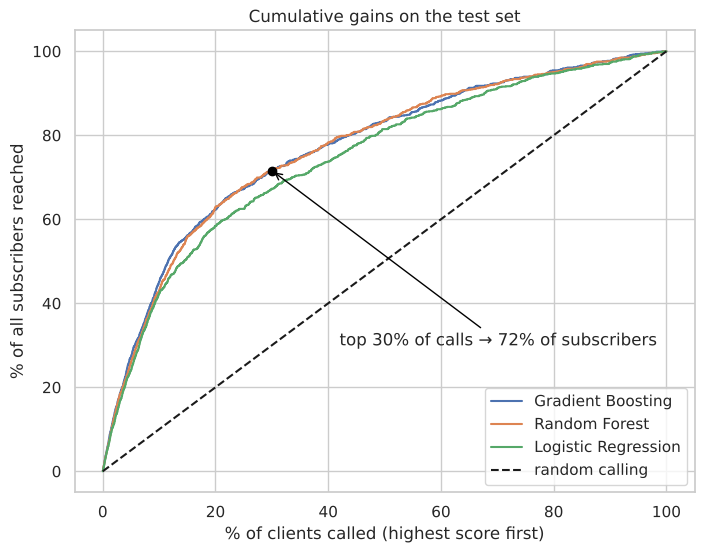

In [8]:
fig, ax = plt.subplots(figsize=(8, 6))
x = np.arange(1, len(probas) + 1) / len(probas) * 100
for col, name in [('gradient_boosting', 'Gradient Boosting'), ('random_forest', 'Random Forest'),
                  ('logistic_regression', 'Logistic Regression')]:
    gains = probas.sort_values(col, ascending=False)['y_true'].cumsum().values / total_yes * 100
    ax.plot(x, gains, label=name)
ax.plot([0, 100], [0, 100], 'k--', label='random calling')
gb30 = value.loc[value['call_top_%'] == 30, 'GB_subscribers_reached_%'].item()
ax.scatter([30], [gb30], color='black', zorder=5)
ax.annotate(f'top 30% of calls → {gb30:.0f}% of subscribers', (30, gb30), xytext=(42, 30),
            arrowprops=dict(arrowstyle='->', color='black'))
ax.set_xlabel('% of clients called (highest score first)')
ax.set_ylabel('% of all subscribers reached')
ax.set_title('Cumulative gains on the test set')
ax.legend(loc='lower right'); plt.show()

## Reading the result

**Threshold:** the F1-optimal threshold chosen on training data is **0.161**. On the test set it lifts recall from 0.25 to **0.56**
and balanced accuracy from 0.62 to **0.73**, while precision drops from 0.66 to **0.44**. In plain words: of every 100 clients the model
says to call, about 44 subscribe, against 12 with random calling.

**Business value** (test set: 9,043 clients, 1,058 subscribers):

| Calls made | Subscribers reached (Gradient Boosting) | Yes rate among called | Random calling |
| --- | --- | --- | --- |
| Top 10% | **45.1%** | 52.8% | 10% |
| Top 20% | **62.4%** | 36.5% | 20% |
| Top 30% | **71.6%** | 27.9% | 30% |
| Top 50% | **83.4%** | 19.5% | 50% |

Calling only the **top 30%** of scored clients reaches **about 72% of all subscribers**, with **70% fewer calls**.
The top 10% alone converts at 52.8%, **4.5× the 11.7% average**. Random Forest gives almost the same curve;
Logistic Regression is a few points lower but still far above random.

In [9]:
value.to_csv('../results/business_value.csv', index=False)
json.dump({'gradient_boosting_threshold': round(threshold, 3)}, open('../results/threshold.json', 'w'), indent=2)